<a href="https://colab.research.google.com/github/SariChiba/El_Turismo_Esta_De_Vuelta/blob/Erika/notebook/turismo_datacenter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# _Análisis de turismo no residente en Argentina_

---
###### **Lo primero que vamos a hacer es importar las librerías que vamos a necesitar para poder correr correctamente el notebook.**

---

3.1. Carga y exploración inicial

---



In [100]:
import pandas as pd #para manipular los archivos
import matplotlib.pyplot as plt #para hacer gráficos
import seaborn as sb #para hacer gráficos
import numpy as np #para realizar operaciones matemáticas

In [101]:
#Vamos a cargar el dataset elegido a través de una url
url = 'https://raw.githubusercontent.com/SariChiba/El_Turismo_Esta_De_Vuelta/main/dataset/turistas-no-residentes-serie.csv'

#A continuación, le pedimos a pandas que lo lea y le asignamos un nombre para crear el dataframe
turmoismo = pd.read_csv(url)

#Ahora vamos a ver el dataframe que acabamos de crear
turismo

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,anio,mes
0,2010-01-01,Aérea,Bolivia,4390,2010,1
1,2010-01-01,Aérea,Brasil,72669,2010,1
2,2010-01-01,Aérea,Chile,14726,2010,1
3,2010-01-01,Aérea,Paraguay,4062,2010,1
4,2010-01-01,Aérea,Uruguay,3512,2010,1
...,...,...,...,...,...,...
5395,2026-08-01,Terrestre,Uruguay,27147,2026,8
5396,2026-08-01,Terrestre,EE.UU. y Canadá,2268,2026,8
5397,2026-08-01,Terrestre,Resto de América,8320,2026,8
5398,2026-08-01,Terrestre,Europa,12908,2026,8


In [102]:
# Definimos una función que recibe un DataFrame y el nombre de la columna a eliminar
def eliminar_columna(df, columna):
    if columna in df.columns:
        df.drop(columns=[columna], inplace=True)
        print(f"Columna '{columna}' eliminada exitosamente.")
    else:
        print(f"La columna '{columna}' no existe en el DataFrame.")

eliminar_columna(turismo, 'observaciones')
turismo.head()
#Tomamos como decision eliminar la columna de observaciones, ya que lla unica informacion que aportaba era datos vacios o provisorios.

La columna 'observaciones' no existe en el DataFrame.


,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,anio,mes
0,2010-01-01,Aérea,Bolivia,4390,2010,1
1,2010-01-01,Aérea,Brasil,72669,2010,1
2,2010-01-01,Aérea,Chile,14726,2010,1
3,2010-01-01,Aérea,Paraguay,4062,2010,1
4,2010-01-01,Aérea,Uruguay,3512,2010,1



---
##### En nuestro grupo, estuvimos de acuerdo que lo primero que queríamos hacer era modificar las fechas para que se lean de la forma en que estamos acostumbrados a hacerlo en Argentina. El objetivo es que el día quede primero y el año último.
##### ¿Por qué el cambio lo realizamos ahora y no más adelante? Más que nada por una cuestión de comodidad visual, preferible hacerlo antes de realizar algún otro cambio que dificulte la conversión más adelante.

In [103]:
#Convertimos la columna indice_tiempo a formato datetime para que pandas la reconozca de la forma correcta
turismo['indice_tiempo'] = pd.to_datetime(turismo['indice_tiempo'])

### ⚠️ Importante
A continuación, utilizamos la ayuda de la **IA** para cambiar del formato YYYY-MM-DD a DD-MM-YYYY.

> _Prompt utilizado: Cambiar el formato de las fechas de YYYY-MM-DD a DD-MM-YYYY_









In [104]:
# Cambiamos el formato de la columna indice_tiempo a DD-MM-YYYY
turismo['indice_tiempo'] = turismo['indice_tiempo'].dt.strftime('%d-%m-%Y')

# Ahora mostramos las primeras filas para verificar que se haya aplicado de forma correcta:
turismo.head(10)


,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,anio,mes
0,01-01-2010,Aérea,Bolivia,4390,2010,1
1,01-01-2010,Aérea,Brasil,72669,2010,1
2,01-01-2010,Aérea,Chile,14726,2010,1
3,01-01-2010,Aérea,Paraguay,4062,2010,1
4,01-01-2010,Aérea,Uruguay,3512,2010,1
5,01-01-2010,Aérea,EE.UU. y Canadá,42783,2010,1
6,01-01-2010,Aérea,Resto de América,36410,2010,1
7,01-01-2010,Aérea,Europa,75995,2010,1
8,01-01-2010,Aérea,Resto del mundo,15212,2010,1
9,01-01-2010,Fluvial/Marítima,Bolivia,2304,2010,1


In [105]:
#Mostramos las últimas filas usando .tail, también seleccionamos 10
turismo.tail(10)

,indice_tiempo,medio_de_transporte,pais_origen,viajes_de_turistas_no_residentes,anio,mes
5390,01-08-2026,Fluvial/Marítima,Resto del mundo,1228,2026,8
5391,01-08-2026,Terrestre,Bolivia,7336,2026,8
5392,01-08-2026,Terrestre,Brasil,34488,2026,8
5393,01-08-2026,Terrestre,Chile,10373,2026,8
5394,01-08-2026,Terrestre,Paraguay,25351,2026,8
5395,01-08-2026,Terrestre,Uruguay,27147,2026,8
5396,01-08-2026,Terrestre,EE.UU. y Canadá,2268,2026,8
5397,01-08-2026,Terrestre,Resto de América,8320,2026,8
5398,01-08-2026,Terrestre,Europa,12908,2026,8
5399,01-08-2026,Terrestre,Resto del mundo,2251,2026,8


In [106]:
print("Dimensiones:", turismo.shape)
print("Columnas :", list(turismo.columns))
print("\nTipos de dato:")
print(turismo.dtypes)

print("MEMORIA  : %.2f MB" % (turismo.memory_usage(deep=True).sum() / 1024**2))

# Convertimos especificando explícitamente el formato original de la columna (día-mes-año) para evitar confusiones de fechas
fecha_min = pd.to_datetime(turismo["indice_tiempo"], format="%d-%m-%Y").min().date()
fecha_max = pd.to_datetime(turismo["indice_tiempo"], format="%d-%m-%Y").max().date()

print("\nPeríodo que cubre:", fecha_min, "→", fecha_max)

cantidad_visitantes_total = turismo['viajes_de_turistas_no_residentes'].sum()
print("\nCantidad total de visitantes no residentes:", cantidad_visitantes_total)

turismo.describe().round(2)

Dimensiones: (5400, 6)
Columnas : ['indice_tiempo', 'medio_de_transporte', 'pais_origen', 'viajes_de_turistas_no_residentes', 'anio', 'mes']

Tipos de dato:
indice_tiempo                       object
medio_de_transporte                 object
pais_origen                         object
viajes_de_turistas_no_residentes     int64
anio                                 int32
mes                                  int32
dtype: object
MEMORIA  : 1.13 MB

Período que cubre: 2010-01-01 → 2026-08-01

Cantidad total de visitantes no residentes: 97999975


,viajes_de_turistas_no_residentes,anio,mes
count,5400.00,5400.00,5400.00
mean,18148.14,2017.84,6.42
std,21317.76,4.81,3.44
min,0.00,2010.00,1.00
25%,3325.00,2014.00,3.00
50%,9184.00,2018.00,6.00
75%,27894.75,2022.00,9.00
max,213862.00,2026.00,12.00


 3.2. Preguntas de investigación

---

 ####  **¿Cómo evolucionó el turismo no residente en Argentina en los últimos años?**





In [107]:
# Obtenemos la cantidad de Visitantes no residentes por año

# Convertir la fecha a formato de fecha correctamente usando pd.to_datetime
turismo['indice_tiempo'] = pd.to_datetime(turismo['indice_tiempo'], format='%d-%m-%Y')

# Crear la columna año
turismo['anio'] = turismo['indice_tiempo'].dt.year

# Sumar los viajes de todos los meses, países y transportes de cada año
visitas_por_anio = (
    turismo.groupby('anio')['viajes_de_turistas_no_residentes']
      .sum()
      .reset_index()
)

# Renombrar las columnas para la presentación
visitas_por_anio.columns = ['Año', 'Cantidad de visitas']

# Creamos una copia formateada visualmente con puntos como separadores de miles
visitas_por_anio_formateado = visitas_por_anio.copy()
visitas_por_anio_formateado['Cantidad de visitas'] = visitas_por_anio_formateado['Cantidad de visitas'].map(lambda x: f"{x:,.0f}".replace(",", "."))

# Mostrar los resultados con el formato de lectura mejorado
display(visitas_por_anio_formateado)

,Año,Cantidad de visitas
0,2010,6.738.593
1,2011,6.674.029
2,2012,6.461.769
3,2013,6.510.286
4,2014,7.165.219
5,2015,6.815.623
6,2016,6.668.207
7,2017,6.711.248
8,2018,6.941.767
9,2019,7.398.973


In [108]:
# Obtenemos el año con mayor cantidad de visitantes de acuerdo a nuestra muestra:

anio_max_visitas = visitas_por_anio.loc[visitas_por_anio['Cantidad de visitas'].idxmax()]

print(f"El año con mayor cantidad de visitantes fue {int(anio_max_visitas['Año'])} con {int(anio_max_visitas['Cantidad de visitas']):,} visitas.")

El año con mayor cantidad de visitantes fue 2019 con 7,398,973 visitas.


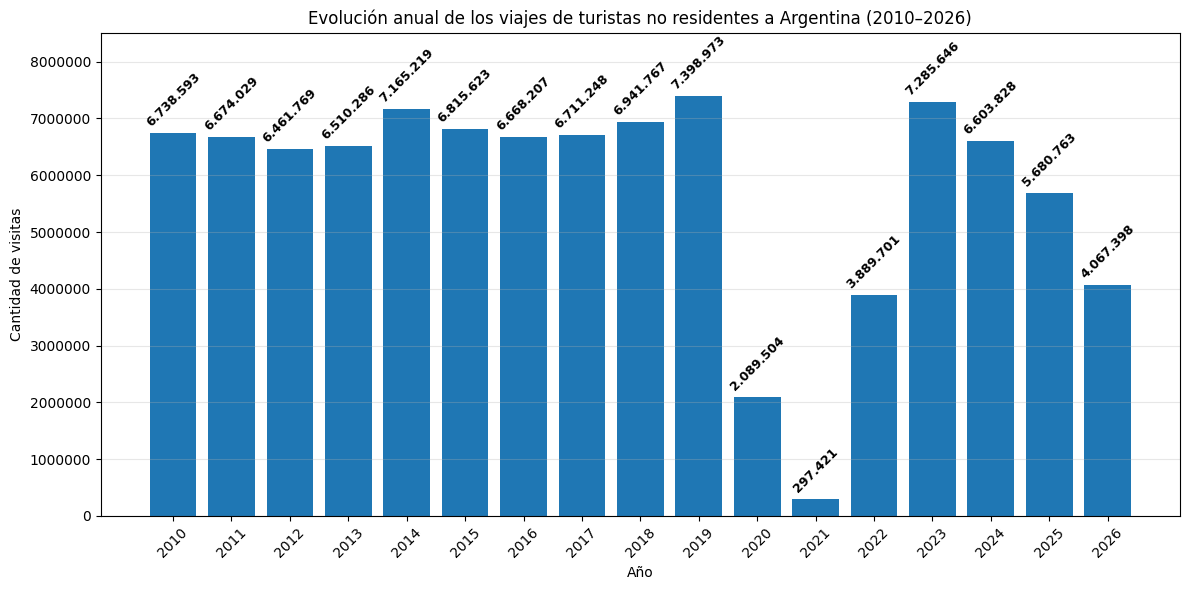

In [109]:
# GRÁFICAMENTE CON ETIQUETAS DE VALORES EN NEGRITA Y FORMATEADAS CON PUNTOS:

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(
    visitas_por_anio['Año'],
    visitas_por_anio['Cantidad de visitas'],
    width=0.8
)

# Crear las etiquetas formateadas con punto como separador de miles
etiquetas_formateadas = [f"{int(valor):,}".replace(",", ".") for valor in visitas_por_anio['Cantidad de visitas']]

# Añadir los valores numéricos sobre cada columna con estilo negrita (weight='bold')
ax.bar_label(bars, labels=etiquetas_formateadas, padding=3, rotation=45, fontsize=9, weight='bold')

plt.title('Evolución anual de los viajes de turistas no residentes a Argentina (2010–2026)')
plt.xlabel('Año')
plt.ylabel('Cantidad de visitas')
plt.xticks(visitas_por_anio['Año'], rotation=45)

# Ajustamos el límite de y para que las etiquetas no se corten
plt.ylim(0, visitas_por_anio['Cantidad de visitas'].max() * 1.15)

plt.ticklabel_format(axis="y", style="plain")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### ¿Cómo interpretar los resultados?

El gráfico muestra la evolución de la cantidad de viajes de turistas no residentes a Argentina entre 2010 y 2026.

Durante el período 2010-2019, se observa un comportamiento relativamente estable, con fluctuaciones moderadas y un máximo de aproximadamente 7,4 millones de viajes en 2019.

En 2020 y 2021 se registra una disminución significativa, coincidente con la pandemia de COVID-19 y las restricciones a los viajes internacionales.

A partir de 2022 se evidencia una recuperación del turismo, alcanzando en 2023 valores cercanos a los registrados antes de la pandemia. Sin embargo, durante 2024 y 2025 se observa una nueva tendencia descendente.

Es importante señalar que los datos correspondientes a 2026 abarcan únicamente hasta agosto, por lo que no pueden compararse directamente con los años completos.

En conclusión, el turismo no residente en Argentina presentó un comportamiento relativamente estable antes de la pandemia, seguido de una fuerte caída, una posterior recuperación y una nueva disminución en los últimos años analizados.

<br>

---
#### **¿Qué países o regiones aportaron más turistas durante el periodo analizado?**


Calculamos la cantidad de viajes por país o región.<br>
Primero agrupamos los datos por pais_origen y sumamos la cantidad de viajes registrados.

In [110]:
# Calcular los viajes por país/región si no se definió previamente
visitas_por_pais = turismo.groupby('pais_origen')['viajes_de_turistas_no_residentes'].sum().sort_values(ascending=False)

# Calcular el porcentaje de visitas de cada país/región respecto al total general
visitas_total_general = visitas_por_pais.sum()
porcentaje_por_pais = (visitas_por_pais / visitas_total_general) * 100

# Crear un DataFrame para mostrar los resultados con formato
# Formateamos la cantidad de visitas con puntos como separador de miles y el porcentaje con '%'
tabla_porcentajes = pd.DataFrame({
    'Cantidad de visitas': visitas_por_pais.map(lambda x: f"{x:,.0f}".replace(",", ".")),
    'Porcentaje (%)': porcentaje_por_pais.round(2).map('{:.2f}%'.format)
})

display(tabla_porcentajes)

,Cantidad de visitas,Porcentaje (%)
pais_origen,,
Brasil,19.206.027,19.60%
Chile,15.868.607,16.19%
Europa,13.424.077,13.70%
Uruguay,12.917.528,13.18%
Paraguay,10.885.956,11.11%
Resto de América,9.241.591,9.43%
EE.UU. y Canadá,7.144.982,7.29%
Bolivia,5.517.186,5.63%
Resto del mundo,3.794.021,3.87%


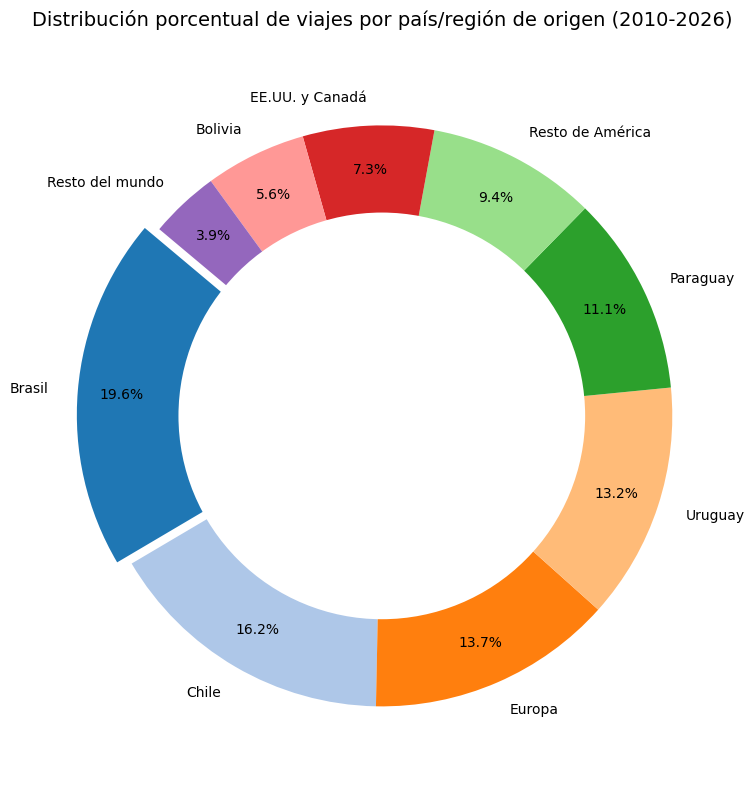

In [111]:
# CREAMOS UN GRÁFICO DE TORTA BASADO EN LA TABLA DE PAÍSES DE ORIGEN

import matplotlib.pyplot as plt

# Nos aseguramos de calcular la variable si no existe en el entorno actual
if 'visitas_por_pais' not in globals():
    visitas_por_pais = turismo.groupby('pais_origen')['viajes_de_turistas_no_residentes'].sum().sort_values(ascending=False)

# Definimos los datos a utilizar
valores = visitas_por_pais.values
etiquetas = visitas_por_pais.index

# Configuración de colores y destacar el primer elemento (Brasil)
colores = ['#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#2ca02c', '#98df8a', '#d62728', '#ff9896', '#9467bd']
explode = [0.05 if i == 0 else 0 for i in range(len(valores))]

plt.figure(figsize=(10, 8))

# Crear el gráfico de torta
plt.pie(
    valores,
    labels=etiquetas,
    autopct='%1.1f%%',
    startangle=140,
    colors=colores,
    explode=explode,
    pctdistance=0.85,
    textprops={'fontsize': 10}
)

# Dibujar un círculo blanco en el centro para transformarlo en un gráfico de dona (mejora la legibilidad)
centro_circulo = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centro_circulo)

plt.title("Distribución porcentual de viajes por país/región de origen (2010-2026)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

### **Análisis de estacionalidad por País/Región de origen**

Para profundizar en el comportamiento de los turistas según su origen, utilizaremos un mapa de calor (Heatmap) que nos permita identificar en qué meses del año se concentran las visitas de cada país o región.

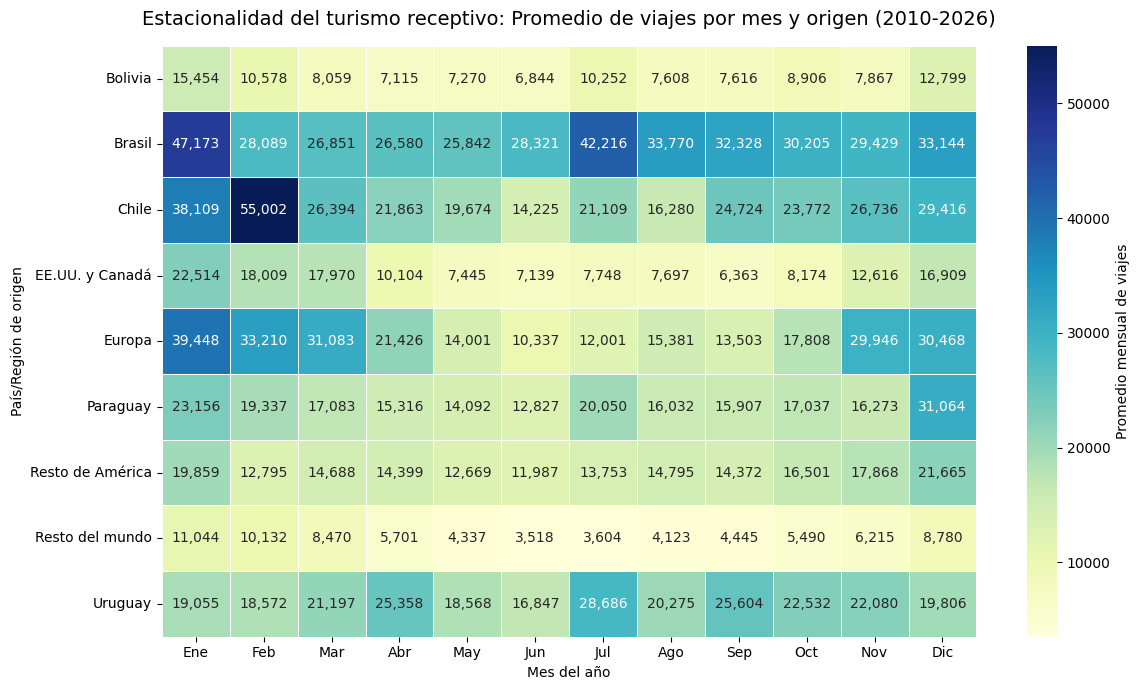

In [112]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pivotamos los datos para tener los países en las filas y los meses en las columnas
heatmap_data = turismo.groupby(['pais_origen', 'mes'])['viajes_de_turistas_no_residentes'].mean().unstack()

# Mapeamos los números de mes a nombres cortos
heatmap_data.columns = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

plt.figure(figsize=(12, 7))
sns.heatmap(
    heatmap_data,
    cmap='YlGnBu',
    annot=True,
    fmt=",.0f",
    linewidths=0.5,
    cbar_kws={'label': 'Promedio mensual de viajes'}
)

plt.title('Estacionalidad del turismo receptivo: Promedio de viajes por mes y origen (2010-2026)', fontsize=14, pad=15)
plt.xlabel('Mes del año')
plt.ylabel('País/Región de origen')
plt.tight_layout()
plt.show()

Se observa que Brasil ocupa el primer lugar, seguido por Chile, Europa, Uruguay y Paraguay.

Estos resultados muestran la importancia de los países limítrofes como mercados emisores de turismo hacia Argentina.

El análisis permite concluir que existe una participación destacada de los países vecinos en el turismo receptivo argentino.

---
### **En el análisis anterior, se observa una caída muy marcada y una posterior recuperación entre el periodo 2019 y 2023 en el marco de la Pandemia COVID-19 que nos lleva a profundizar nuestro análisis:**

Calculamos cuánto disminuyó el turismo entre 2019 y 2023:

In [113]:
# Primero definimos 'viajes_pandemia' a partir de 'visitas_por_anio' para el rango 2019-2023
# Filtramos los años de interés y establecemos el Año como índice
viajes_pandemia = visitas_por_anio[
    (visitas_por_anio['Año'] >= 2019) & (visitas_por_anio['Año'] <= 2023)
].set_index('Año')['Cantidad de visitas']

# Tomar 2019 como referencia
viajes_2019 = viajes_pandemia.loc[2019]

# Calcular variación respecto a 2019
variacion = (
    (viajes_pandemia / viajes_2019) - 1
) * 100

print("Variación respecto a 2019:")
variacion.round(2).map("{:+.2f}%".format)

Variación respecto a 2019:


,Cantidad de visitas
Año,
2019,+0.00%
2020,-71.76%
2021,-95.98%
2022,-47.43%
2023,-1.53%


### **Impacto de la pandemia en el turismo no residente en Argentina**

El análisis de los viajes de turistas no residentes entre 2019 y 2023 evidencia una fuerte disminución durante los años de la pandemia de COVID-19.

En 2019 se registraron aproximadamente 7,4 millones de viajes, mientras que en 2020 esta cifra descendió a 2,1 millones. La caída se profundizó en 2021, cuando se alcanzó un mínimo de aproximadamente 297 mil viajes, equivalente a una disminución del 96% respecto de 2019.

Durante 2022 se observó una recuperación significativa, con aproximadamente 3,9 millones de viajes registrados. Sin embargo, esta cifra todavía se encontraba un 47,4% por debajo del nivel previo a la pandemia.

En 2023, los viajes alcanzaron aproximadamente 7,3 millones, acercándose a los valores de 2019.

Estos resultados muestran una fuerte ruptura en la evolución del turismo receptivo argentino durante la pandemia y una recuperación progresiva en los años posteriores. Aunque la caída coincide temporalmente con las restricciones a la movilidad internacional, los datos analizados por sí solos no permiten determinar cuánto de esa disminución fue causado por cada factor.

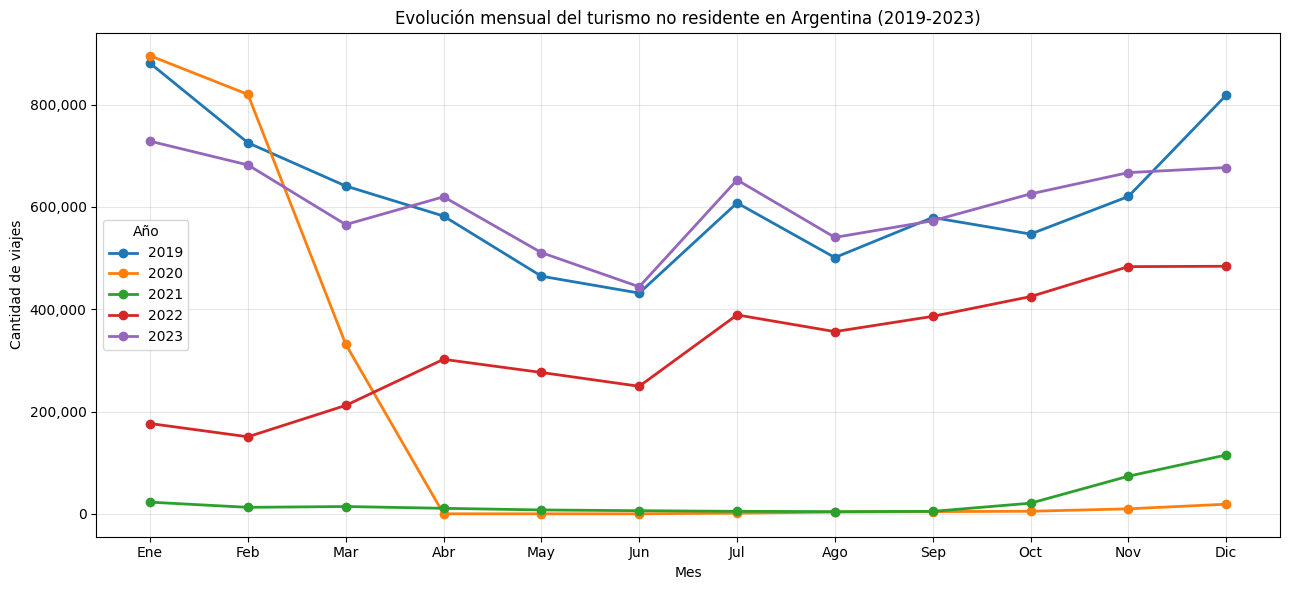

In [114]:

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Convertir fecha
#turismo["indice_tiempo"] = pd.to_datetime(turismo["indice_tiempo"])

# Crear columnas de año y mes
#turismo["anio"] = turismo["indice_tiempo"].dt.year
turismo["mes"] = turismo["indice_tiempo"].dt.month

# Filtrar los años de interés
datos = turismo[turismo["anio"].between(2019, 2023)]

# Agrupar viajes por mes y año
comparacion = (
    datos.groupby(["mes", "anio"])[
        "viajes_de_turistas_no_residentes"
    ]
    .sum()
    .unstack()
)

# Crear gráfico
plt.figure(figsize=(13, 6))

for anio in comparacion.columns:
    plt.plot(
        comparacion.index,
        comparacion[anio],
        marker="o",
        linewidth=2,
        label=str(anio)
    )

plt.title(
    "Evolución mensual del turismo no residente "
    "en Argentina (2019-2023)"
)

plt.xlabel("Mes")
plt.ylabel("Cantidad de viajes")

plt.xticks(
    range(1, 13),
    ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
     "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x:,.0f}")
)

plt.legend(title="Año")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("lineas_superpuestas_pandemia.png", dpi=300)
plt.show()


Cada línea representa un año diferente, y cada punto muestra los viajes registrados durante un mes.

De esta manera, podemos comparar cómo se comportó el turismo en un mismo mes durante distintos años.

### Relación entre el mes del año y la cantidad de viajes turísticos

El gráfico de líneas superpuestas permite analizar la relación entre el mes del año y la cantidad de viajes de turistas no residentes a Argentina, comparando el comportamiento de esta variable entre 2019 y 2023.

La utilización de líneas diferenciadas por año permite identificar cambios en la evolución mensual del turismo durante la pandemia y su posterior recuperación.

La comparación con 2019, considerado como período de referencia previo a la pandemia, permite evaluar la magnitud de la disminución registrada en 2020 y 2021, así como el grado de recuperación observado durante 2022 y 2023.

Además, el análisis permite investigar la existencia de patrones estacionales y determinar si el comportamiento mensual del turismo recuperó características similares a las observadas antes de la pandemia.